[![Ouvrir dans Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/philippe-amuzuga/Meca-IA_Ed2026/blob/main/meca-ia/C13/E13-2_Pompe_Similitude_CORRIGE.ipynb)

# Puissance d'une pompe : empiler des couches de neurones

## Le contexte

La puissance qu'une pompe absorbe à son arbre décide du moteur à installer et de la facture d'énergie. Elle dépend du débit, de la vitesse de rotation, du diamètre de la roue et du fluide, par une loi de similitude et par un rendement qui varie avec le point de fonctionnement. Le banc d'essai de la section précédente a relevé 800 points de fonctionnement ; cette fois, la cible est la puissance. Le bureau d'études voudrait la prédire sans écrire la loi.

La grandeur à prédire est une puissance en kW : c'est un problème de régression.

Défi : prédire `puissance_kW` et obtenir un R² supérieur à celui du modèle de départ sur la base de test. Ce modèle de départ est le neurone isolé de la section précédente, une somme pondérée des entrées, ici résolue directement par une régression linéaire ; il atteint un R² de 0,74. À vous d'empiler des couches de neurones. La règle de découpage est fixée plus bas, et c'est celle du défi précédent. La base de test sert à mesurer, jamais à apprendre ni à régler.

## Les données

Fichier `MecaIA-Pompe_Similitude.xlsx`, dans le dossier `donnees` du dépôt : 800 mesures, 6 colonnes. Une ligne est un point de fonctionnement mesuré sur un banc d'essai de pompe. C'est le jeu de la section précédente, avec l'autre cible.

| Colonne | Signification | Unité |
|---|---|---|
| `fluide` | fluide pompé : `eau` ou `huile`, plus visqueuse | catégorie |
| `diametre_roue_mm` | diamètre extérieur de la roue | mm |
| `vitesse_rpm` | vitesse de rotation de l'arbre | tr/min |
| `debit_m3_h` | débit traversant la pompe | m³/h |
| `hauteur_m` | hauteur manométrique mesurée, première cible du jeu, écartée ici : la puissance s'en déduit, la donner au modèle reviendrait à lui donner la réponse | m |
| `puissance_kW` | cible : puissance absorbée à l'arbre | kW |

Origine : jeu simulé, d'après les lois de similitude des pompes centrifuges, avec une dispersion d'une pompe à l'autre et le bruit des capteurs. Quelques vitesses de rotation ne sont pas relevées. Il enseigne une méthode, et aucune conclusion d'hydraulique n'en découle.

### Étape 1 : charger le fichier et regarder sa forme

On lit le classeur, puis on vérifie ses dimensions, ses cases vides et la plage de la cible avant toute modélisation : la forme d'un fichier se lit sur le fichier entier. Le dossier des données est cherché depuis le dossier du notebook, puis depuis un clone du dépôt ; ouvert seul, par exemple dans Colab, le notebook télécharge une fois le jeu depuis le dépôt public.

In [1]:
from pathlib import Path
import urllib.request

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn import set_config

set_config(display="text")
GRAINE = 42
FICHIER = "MecaIA-Pompe_Similitude.xlsx"
URL_JEU = "https://raw.githubusercontent.com/philippe-amuzuga/Meca-IA_Ed2026/main/donnees/MecaIA-Pompe_Similitude.xlsx"

# Le dossier `donnees` du dépôt, cherché depuis le dossier du notebook, puis depuis un clone.
candidats = [Path("..", "..", "donnees"), Path("Meca-IA_Ed2026", "donnees")]
dossier = next((d for d in candidats if (d / FICHIER).is_file()), None)
if dossier is None:
    # Notebook ouvert seul (Colab) : copie unique du jeu depuis le dépôt public.
    dossier = Path("donnees")
    dossier.mkdir(exist_ok=True)
    try:
        urllib.request.urlretrieve(URL_JEU, dossier / FICHIER)
    except OSError as erreur:
        raise FileNotFoundError(
            "Jeu introuvable : clonez le dépôt, ou vérifiez la connexion pour le télécharger.") from erreur
df = pd.read_excel(dossier / FICHIER)

cible = "puissance_kW"
categories = ["fluide"]
mesures = ["diametre_roue_mm", "vitesse_rpm", "debit_m3_h"]
print("dimensions :", df.shape)
vides = df.isna().sum()
print("cases vides :", vides[vides > 0].to_dict())
print(df[cible].describe().round(1).to_dict())
df.head(3)

dimensions : (800, 6)
cases vides : {'vitesse_rpm': 21}
{'count': 800.0, 'mean': 12.1, 'std': 16.4, 'min': 0.1, '25%': 2.3, '50%': 6.0, '75%': 15.1, 'max': 103.3}


,fluide,diametre_roue_mm,vitesse_rpm,debit_m3_h,hauteur_m,puissance_kW
0,huile,180,3358.0,32.0,37.0,5.26
1,eau,166,2071.0,5.9,14.6,0.62
2,eau,195,2809.0,70.0,19.0,4.89


Lecture du résultat : 800 mesures, 6 colonnes. La vitesse de rotation compte 21 cases vides, qu'il faudra remplir. La puissance va de 0,10 à 103,3 kW, pour une médiane de 6,0 kW et une moyenne de 12,1 kW : elle s'étend sur plus de 3 puissances de dix, et les grandes valeurs sont rares.

### Préparation du dépôt (Colab)

Ouvert seul dans Colab, ce notebook ne voit pas le dossier `donnees/` du dépôt. La cellule suivante ne télécharge rien : elle cherche ce dossier (à deux dossiers au-dessus du notebook, à côté de lui ou dans un clone nommé `Meca-IA_Ed2026`), vérifie la présence du classeur du défi et, sur Colab, liste ce qui manque. Pour le fournir, ouvrez le panneau des fichiers de Colab, créez le dossier `donnees` à la racine de l'espace de travail et téléversez-y le classeur listé, pris dans le dépôt.

In [ ]:
# Préparation du dépôt (utile sur Colab) : cette cellule ne télécharge rien.
import os
from pathlib import Path

JEUX_LUS = ["MecaIA-Pompe_Similitude.xlsx"]                  # le classeur lu par ce notebook


def chercher(dossier):
    """Le dossier du dépôt cherché depuis le notebook, puis depuis un clone ; None s'il est introuvable."""
    for base in (Path("..", ".."), Path("."), Path("Meca-IA_Ed2026")):
        if (base / dossier).is_dir():
            return base / dossier
    return None


donnees = chercher("donnees")
manque = [f"donnees/{nom}" for nom in JEUX_LUS if donnees is None or not (donnees / nom).is_file()]
if manque and "COLAB_RELEASE_TAG" in os.environ:          # variable posée par Colab
    print("À téléverser dans l'espace de travail de Colab, panneau des fichiers :")
    print("\n".join("  " + nom for nom in manque))


### Étape 2 : mettre le test de côté

Un quart des mesures est mis de côté avant tout apprentissage, tout réglage et toute comparaison avec la cible. La graine 42 fixe le tirage : chacun obtient la même base de test, et les scores se comparent. La hauteur, première cible du jeu, ne sert pas d'entrée.

In [2]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=["hauteur_m", "puissance_kW"])
y = df[cible]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=GRAINE)
print("apprentissage :", len(X_train), "mesures")
print("test :", len(X_test), "mesures")

apprentissage : 600 mesures
test : 200 mesures


### Étape 3 : regarder la puissance contre le débit sur l'apprentissage

La puissance couvre plusieurs puissances de dix : la figure la place en échelle logarithmique, avec un symbole par fluide.

débit entre 40 et 60 m³/h : 95 mesures, puissance de 0.74 à 30.0 kW


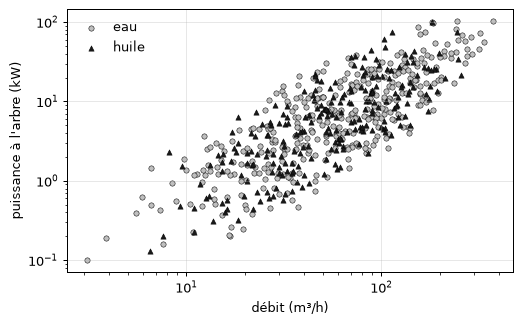

In [3]:
fig, ax = plt.subplots(figsize=(6.4, 3.8))
for fluide, marque, gris in [("eau", "o", "0.75"), ("huile", "^", "0.1")]:
    choix = X_train["fluide"] == fluide
    ax.scatter(X_train.loc[choix, "debit_m3_h"], y_train[choix], s=18, marker=marque, color=gris,
               edgecolor="black", linewidth=0.4, label=fluide)
ax.set(xlabel="débit (m³/h)", ylabel="puissance à l'arbre (kW)", xscale="log", yscale="log")
ax.legend(frameon=False)
ax.grid(alpha=0.3)
plt.show()
bande = (X_train["debit_m3_h"] > 40) & (X_train["debit_m3_h"] < 60)
print(f"débit entre 40 et 60 m³/h : {bande.sum()} mesures, puissance de {y_train[bande].min():.2f} à {y_train[bande].max():.1f} kW")

Lecture du résultat : la puissance croît avec le débit, mais le nuage est large : à débit voisin (entre 40 et 60 m³/h), elle va de 0,74 à 30,0 kW, un rapport de 41. La vitesse de rotation et le diamètre de la roue interviennent aussi, et d'une façon qui n'est pas une somme. Un modèle qui additionne les entrées avec un poids chacune ne pourra suivre qu'une partie de cette loi.

### Étape 4 : préparer les entrées

Le fluide devient une colonne de 0 et de 1, les vitesses non relevées sont remplacées par la médiane de l'apprentissage, et chaque entrée est ramenée à une moyenne nulle et à un écart type de 1. Un réseau, comme un neurone, apprend mal quand ses entrées n'ont pas la même échelle. La préparation s'apprend sur `X_train` seul et s'applique ensuite au test.

In [4]:
# Solution :
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

preprocessor = make_column_transformer(
    (OneHotEncoder(drop="if_binary"), categories),
    (make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), mesures))
# Fin de la solution

### Étape 5 : construire le modèle de départ

Le modèle de départ est le neurone isolé de la section précédente : une somme pondérée des entrées plus un biais, sans couche cachée. La descente de gradient de la section précédente en trouve la solution, que la régression linéaire donne directement : c'est elle qu'on emploie ici. Le pipeline prépare les entrées puis ajuste la droite, sur `X_train` seul.

In [5]:
# Solution :
from sklearn.linear_model import LinearRegression

modele = make_pipeline(preprocessor, LinearRegression())
modele.fit(X_train, y_train)
# Fin de la solution

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('onehotencoder',
                                                  OneHotEncoder(drop='if_binary'),
                                                  ['fluide']),
                                                 ('pipeline',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['diametre_roue_mm',
                                                   'vitesse_rpm',
                                                   'debit_m3_h'])])),
                ('linearregression', LinearRegression())])

### Étape 6 : mesurer sur la base de test

Le modèle prédit les mesures qu'il n'a jamais vues. Trois indicateurs sont lus : le coefficient de détermination R², et deux erreurs en kW, la racine de l'erreur quadratique moyenne (RMSE) et l'erreur absolue moyenne (MAE). Un témoin sans apprentissage, qui répond toujours la moyenne de l'apprentissage, donne le point de comparaison le plus bas.

In [6]:
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error

y_pred = modele.predict(X_test)
score_depart = r2_score(y_test, y_pred)
score_temoin = r2_score(y_test, np.full(len(y_test), y_train.mean()))
print(f"R² : {score_depart:.3f}")
print(f"RMSE : {root_mean_squared_error(y_test, y_pred):.2f} kW")
print(f"MAE : {mean_absolute_error(y_test, y_pred):.2f} kW")
print(f"R² du témoin (toujours la moyenne de l'apprentissage) : {score_temoin:.3f}")
print(f"prédictions négatives : {(y_pred < 0).sum()} sur {len(y_pred)}")

R² : 0.735
RMSE : 9.12 kW
MAE : 5.71 kW
R² du témoin (toujours la moyenne de l'apprentissage) : -0.007
prédictions négatives : 30 sur 200


Lecture du résultat : le R² est de 0,74 et l'erreur absolue moyenne de 5,71 kW, pour une puissance moyenne de 13,3 kW sur la base de test. Le témoin, qui répond toujours la moyenne, n'explique rien : son R² est nul, au signe de l'arrondi près. La droite prédit même une puissance négative pour 30 mesures sur 200, ce qu'aucune pompe ne fait : elle ne suit pas la courbure de la loi. C'est ce chiffre, mesuré sur des mesures que le modèle n'a jamais vues, que l'on a le droit d'annoncer.

## Pour aller plus loin : empiler des couches

Le modèle de départ de l'étape 5 reste le score de référence du défi. Les deux cellules suivantes montrent comment le dépasser sans regarder le test pour choisir. La première compare, par validation croisée sur l'apprentissage seul, un neurone sans couche cachée, une couche cachée de plus en plus large, puis deux couches empilées. La cible est mise à l'échelle avant l'apprentissage et ramenée à ses kW ensuite ; la fin de la liste compare le réseau aux réglages par défaut, avec et sans cette mise à l'échelle. La seconde mesure le modèle retenu une seule fois sur le test. Les valeurs sont lues dans les sorties imprimées.

In [7]:
# Solution :
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import KFold, cross_val_score
from sklearn.neural_network import MLPRegressor


def reseau(tailles):
    """Réseau de scikit-learn : couches cachées de la taille demandée, cible mise à l'échelle."""
    mlp = MLPRegressor(hidden_layer_sizes=tailles, max_iter=2000, random_state=GRAINE)
    return TransformedTargetRegressor(make_pipeline(preprocessor, mlp), transformer=StandardScaler())


plis = KFold(n_splits=5, shuffle=True, random_state=GRAINE)
candidats = {
    "un neurone, aucune couche cachée": reseau(()),
    "1 couche de 4 neurones": reseau((4,)),
    "1 couche de 16 neurones": reseau((16,)),
    "1 couche de 64 neurones": reseau((64,)),
    "2 couches de 64 neurones": reseau((64, 64)),
    "réseau par défaut, cible brute": make_pipeline(preprocessor, MLPRegressor(random_state=GRAINE)),
    "réseau par défaut, cible à l'échelle": TransformedTargetRegressor(
        make_pipeline(preprocessor, MLPRegressor(random_state=GRAINE)), transformer=StandardScaler())}
notes_cv = {}
for nom, candidat in candidats.items():
    notes = cross_val_score(candidat, X_train, y_train, cv=plis, scoring="r2")
    notes_cv[nom] = notes.mean()
    print(f"{nom} : R² {notes.mean():.3f} +/- {notes.std():.3f} sur 5 plis")
nom_retenu = max(notes_cv, key=notes_cv.get)
print("modèle retenu par la validation croisée :", nom_retenu)
# Fin de la solution

un neurone, aucune couche cachée : R² 0.683 +/- 0.060 sur 5 plis
1 couche de 4 neurones : R² 0.921 +/- 0.026 sur 5 plis
1 couche de 16 neurones : R² 0.952 +/- 0.017 sur 5 plis
1 couche de 64 neurones : R² 0.971 +/- 0.012 sur 5 plis
2 couches de 64 neurones : R² 0.987 +/- 0.006 sur 5 plis
réseau par défaut, cible brute : R² 0.870 +/- 0.025 sur 5 plis
réseau par défaut, cible à l'échelle : R² 0.969 +/- 0.011 sur 5 plis
modèle retenu par la validation croisée : 2 couches de 64 neurones


In [8]:
# Solution :
retenu = candidats[nom_retenu].fit(X_train, y_train)
r2_retenu = r2_score(y_test, retenu.predict(X_test))
print(f"{nom_retenu}, mesuré une fois sur le test : R² {r2_retenu:.3f}")
print(f"gain sur le modèle de départ : {r2_retenu - score_depart:+.3f}")
# Fin de la solution

2 couches de 64 neurones, mesuré une fois sur le test : R² 0.925
gain sur le modèle de départ : +0.189


Lecture du résultat : en validation croisée, un neurone sans couche cachée atteint un R² de 0,68, et une seule couche de 4 neurones monte déjà à 0,92. Élargir la couche continue d'aider (0,95 pour 16 neurones, 0,97 pour 64), et empiler deux couches de 64 neurones donne le meilleur résultat, 0,99. Le même réseau aux réglages par défaut passe de 0,87 à 0,97 quand on met la cible à l'échelle : ce réglage-là coûte une ligne et rapporte 0,10 de R². Le modèle retenu, mesuré une seule fois sur le test, atteint un R² de 0,92, soit 0,19 de plus que le modèle de départ.

## Le score de référence

Le score publié est le R² du modèle de départ de l'étape 5 sur la base de test. L'empreinte identifie cette base de test : si la vôtre diffère, le découpage n'est pas le même et les scores ne se comparent pas.

In [9]:
import hashlib

score = r2_score(y_test, modele.predict(X_test))
positions = ",".join(str(i) for i in sorted(X_test.index))
print("EMPREINTE_TEST =", hashlib.sha256(positions.encode("ascii")).hexdigest())
print("SCORE_REFERENCE r2 = %.2f" % score)

EMPREINTE_TEST = 2218d845347515845d1aba0c1291e1084d84d0f9808829ef716ffc0f10b99e6f
SCORE_REFERENCE r2 = 0.74


## Synthèse

1. Un neurone sans couche cachée est une régression linéaire : il ne suit pas la courbure d'une loi de similitude (R² de 0,74 sur la puissance, avec des puissances négatives prédites).
2. Une couche cachée de quelques neurones suffit à courber la loi ; l'élargir, puis empiler une seconde couche, améliore encore la validation croisée (0,99 pour deux couches de 64 neurones).
3. Les entrées et la cible se mettent à l'échelle avant l'apprentissage : sans cela, le réseau de scikit-learn aux réglages par défaut reste à 0,87 en validation croisée, contre 0,97 avec elle.
4. Le choix de l'architecture se fait par validation croisée sur l'apprentissage ; le test ne sert qu'une fois, au modèle retenu (0,92 ici).